# AI651 Assignment 2 — Question 1

River forecasting proposal. No training is required for this question. The diagram is shown in the cell below.

**Student:** Osama Atiq (25280091)

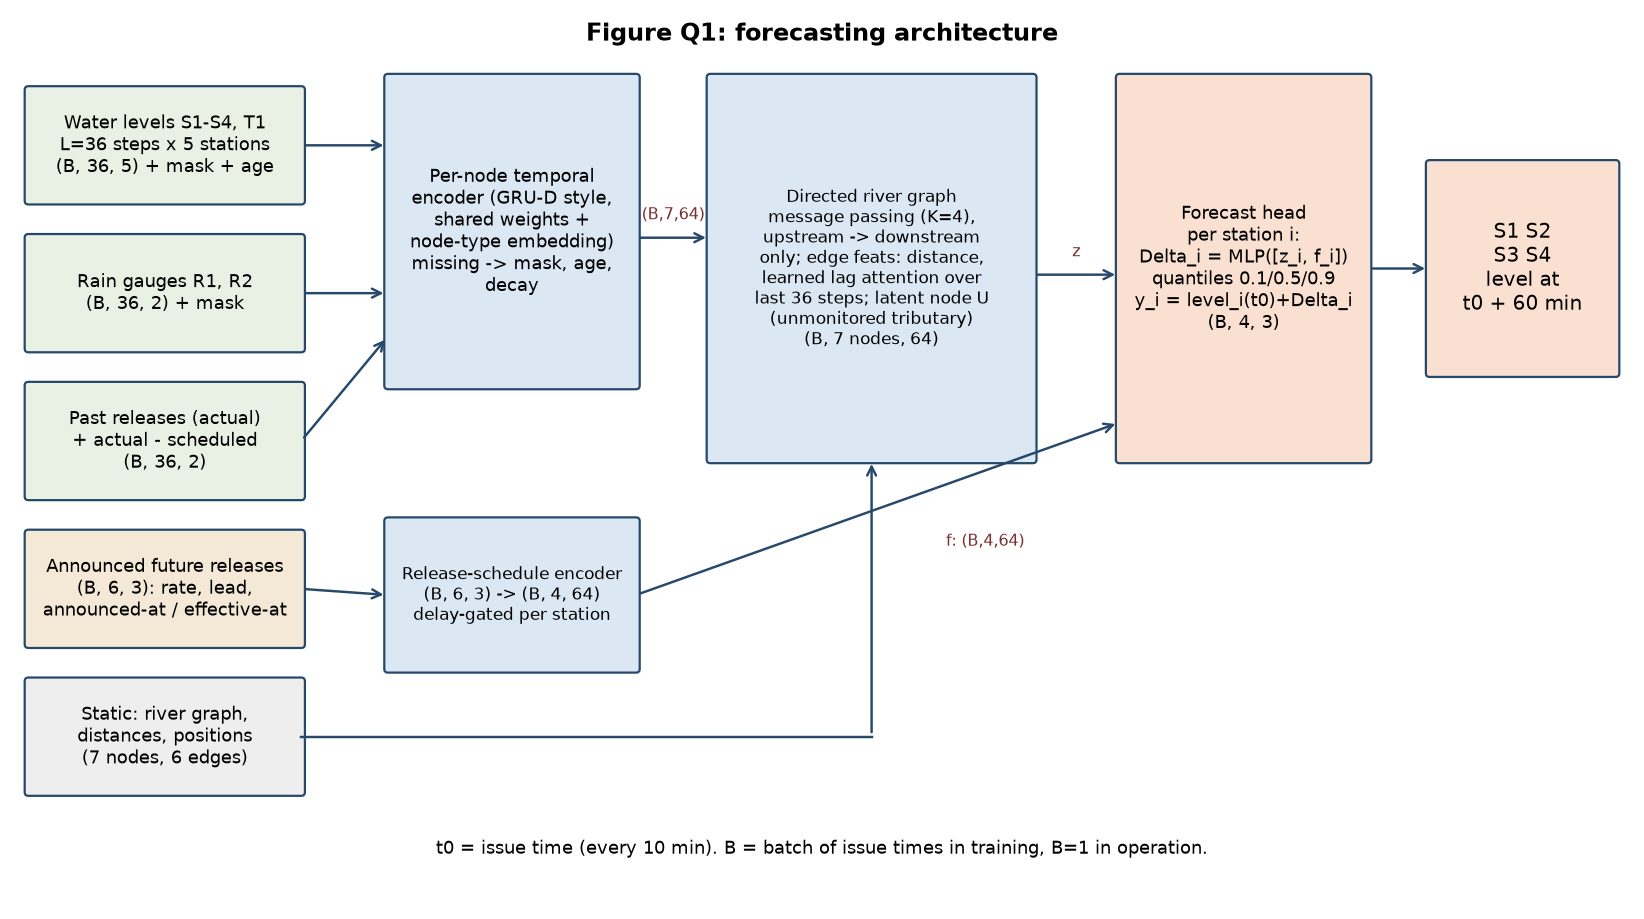

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/q1_architecture.png'))

# Question 1 — River Forecasting Proposal

**Proposal in one line.** A small directed-graph forecaster: each station is a node, a shared temporal encoder summarises its last 6 hours, messages flow only downstream along the river with learned, state-dependent travel delays, announced reservoir releases enter as known future inputs, and each station outputs the 60-minute level change with 10/50/90 % quantiles.

## 1. Architecture diagram

Alignment, projection and reshaping used to combine inputs: (i) all series are resampled to the 10-minute issue grid and stacked as `(B, 36, node)`; (ii) a shared per-node GRU encoder with a node-type embedding projects every node's 36-step history to a 64-d vector, so levels, rain and release are all `(B, 7, 64)` after encoding; (iii) rain-gauge vectors are projected onto the river nodes with a learned distance kernel; (iv) the announced-release sequence `(B, 6, 3)` is projected to `(B, 4, 64)` (one vector per station, delay-gated, see Q4); (v) the head concatenates `z_i` and `f_i` to `(B, 4, 128)` and outputs `(B, 4, 3)`.

## 2. Assumptions

Supplied facts (not assumptions): four main-river stations S1–S4 and tributary station T1; water levels every 10 min; rain gauges R1, R2; reservoir release record and announced future releases (with announcement and effective times); station positions, connectivity and along-river distances; no future rain or levels at issuance; the unmonitored tributary joins between S2 and S3; T1 joins between S1 and S2.

| # | Assumption | Why reasonable | Effect on design |
|---|---|---|---|
| A1 | Forecasts are issued at every 10-min tick t0 using only data that has *arrived* by t0. | Operational definition of the service. | Features carry both measurement time and arrival time. |
| A2 | Levels are in a common datum; each station has a stable level-to-discharge relationship over the training period. | Authority gauges are surveyed. | Model works in normalised level; no rating curve needed (requested in Q6 as an upgrade). |
| A3 | Reporting delay is 0–30 min for most sensors; 5 % of readings are missing and outages of 1–6 h occur. | Typical telemetry behaviour; unspecified in the brief. | Mask + age features, random delay/mask augmentation in training. |
| A4 | Measurement noise is about 1–2 cm with occasional spikes. | Typical for radar/pressure gauges. | Huber-type loss; median-filter spikes flagged by a z-score test. |
| A5 | Flow is one-directional along the river (no back-water except at flood stage). | Steep, confined river as pictured. | Message passing only upstream to downstream. Violations are covered in Q6. |
| A6 | Travel time between two stations is `d / c`, where wave speed `c` rises with discharge (higher level, faster travel). | Standard kinematic-wave behaviour. | Lag attention with a state-dependent speed prior rather than fixed lags. |
| A7 | The unmonitored tributary inflow is a lagged, smoothed response to the same rain that drives T1 and rain gauges. | It is a neighbouring catchment in the same region. | Latent node U driven by rain and T1; its inflow is never observed and shows up as uncertainty. |
| A8 | Rain falling over the next hour is unknown, but rain that already fell upstream is on its way. | Catchment response lags rainfall by tens of minutes to hours. | A 60-min horizon is mostly determined by past rain, upstream levels and the release schedule. |
| A9 | Announced releases are mostly honoured but may be late or differ in size. | Operational reality at dams. | Schedule enters as a feature together with a learned deviation process (Q5 iv). |
| A10 | Rain is a point value at R1 and R2 and represents the surrounding reach. | Only two gauges exist. | Learned distance kernel; the rain field's spatial error is carried as uncertainty. |

## 3. Forecasting task and data specification

**Issuance time.** Every 10 minutes, t0 ∈ {…, 00:00, 00:10, …}. **History window.** L = 36 steps (6 h: t0−350 min … t0), which covers the travel time from reservoir to S4 under all but the slowest flows. **Output.** Water level at t0+60 min at S1–S4 (point forecast plus 10 %, 50 % and 90 % quantiles).

| Tensor | Shape | Axes | Time coverage / alignment |
|---|---|---|---|
| Water levels `W` (S1–S4, T1) | (B, 36, 5) | batch of issue times, time step, station | measurement timestamps t0−350 … t0 on the 10-min grid; late arrivals inserted by *measurement* time |
| Level mask & age `m, a` | (B, 36, 5) × 2 | same | m=1 if the reading had arrived by t0; a = minutes since last arrived reading |
| Rain `P` (R1, R2) | (B, 36, 2) | batch, time, gauge | accumulation over each 10-min bin; mask as above |
| Past release `Q_act`, deviation `Q_act − Q_sched` | (B, 36, 2) | batch, time, {actual, deviation} | measurement time |
| Announced future releases `Q_ann` | (B, 6, 3) | batch, future step t0+10…t0+60, {scheduled rate, effective-minus-announced lead, hours since announcement} | only announcements with announcement time ≤ t0 |
| Static graph `G` | 7 nodes, 6 edges | Res, S1, S2, T1, U, S3, S4 | distances d_ij, station positions, rain-gauge distances to nodes |
| **Output** `Ŷ` | (B, 4, 3) | batch, station S1–S4, quantile {0.1, 0.5, 0.9} | level at t0+60 min; B = 1 in operation, B = batch of issue times in training |

**Alignment.** Stations are unevenly spaced and sampled on the same 10-min grid, so *time* is aligned by the grid and *space* by the graph: spatial offsets are not removed by shifting the series but handled by edge-wise lag attention (travel time ≈ d_ij / c). Missing times are kept as masked slots, never interpolated silently. **Available at issuance:** everything with arrival time ≤ t0 and the announced schedule up to t0. **Not available:** future rain, future levels at any station, release changes announced after t0.

## 4. Model computations and design justification

**Notation.** Node i ∈ {Res, S1, S2, T1, U, S3, S4}, time step τ = 1…36, x_{i,τ} the node's input vector, ℓ_i(t0) the latest level, z_i the node state, e_ij the edge feature (distance d_ij, learned wave-speed prior), σ the sigmoid.

**Temporal encoder (GRU-D style, shared).** For observed readings the input is `[ℓ, m, a, rain/release channels, node-type embedding]`; for missing readings the value decays to the empirical mean: `x̃ = m·x + (1−m)(γ x_last + (1−γ) x̄)`, with `γ = exp(−max(0, W_γ a + b_γ))`. Then `h_{i,τ} = GRU(x̃_{i,τ}, h_{i,τ−1})`.

**Rain projection.** `p_i = Σ_g κ(d_{gi}) · P_g`, with κ a learned positive kernel of gauge-to-node distance (soft-max-normalised over gauges); this gives each river node a rain input although there are only 2 gauges.

**Directed message passing with state-dependent delay (K = 4 layers).** For edge j → i, wave speed `c_ij = c0_ij · softplus(w^T h_{j,36})` (faster when the upstream state is high), expected lag `λ_ij = d_ij / c_ij`. A lag-attention read picks the upstream history near that lag:

`α_{ij,τ} = softmax_τ( −(t0 − τ·10min − λ_ij)² / 2s² )`, `r_ij = Σ_τ α_{ij,τ} h_{j,τ}`, 

`m_ij = φ([r_ij, h_{i,36}, e_ij])`, `z_i^{(k+1)} = z_i^{(k)} + ψ(z_i^{(k)}, Σ_{j→i} m_ij)`.

Messages go only from upstream to downstream, so after K = 4 layers S4 can use Res → S1 → S2 → S3 (the whole chain). The latent node U has no sensor; its state is produced by `z_U = ψ_U(p_U, h_{T1,·})` (rain plus T1's behaviour), and it feeds S3 through an edge like any other.

**Release schedule.** For station i with reservoir-to-station travel time λ_{Res,i}, only schedule entries effective at `t* ≤ t0 + 60 − λ_{Res,i}` can influence its forecast. An announcement s with effective time e_s reaches station i at e_s + λ_{Res,i}, so the encoder uses the gate `g_{i,s} = σ(ω (t0 + 60 min − e_s − λ_{Res,i}))` (ω learned, large and positive), giving `f_i = Σ_s g_{i,s} · u(Q_ann,s)` with u an MLP. S1 therefore sees almost the whole schedule, S4 only its early part.

**Forecast mapping.** `Δ_{i,q} = MLP_q([z_i, f_i])`, `ŷ_{i,q} = ℓ_i(t0) + Δ_{i,q}`; predicting the *change* from the current level (a persistence baseline plus correction) makes the task easier and keeps the output on the right scale.

**Training objective.** `L = Σ_i Σ_{q∈{.1,.5,.9}} ρ_q(y_i − ŷ_{i,q}) + β · Σ_i max(0, −∂ŷ_{i,.5}/∂Q_sched)`; ρ_q is the pinball loss; the second term is a hinge penalty asking more scheduled release not to lower downstream levels (a physical sign constraint). Random masking and delay noise (A3) and schedule perturbation (A9) are applied during training.

**Justification.** *Upstream conditions:* S_{i−1}, S_{i−2}, … reach S_i through lag-attended messages, because downstream levels one hour ahead mostly equal upstream levels one travel-time earlier. *Tributaries:* T1 is an input node joining the S1–S2 reach; the unmonitored one is latent node U. *Rainfall:* enters as projected rain p_i and drives U, with delay learned through the GRU histories. *Reservoir releases:* past actual releases through the encoder of the Res node, announced ones through f_i. **Physical vs learned:** the graph, direction of flow, the travel-time form `λ = d/c` and the sign constraint are physical; the wave-speed function, rainfall–runoff response, latent inflow and deviation behaviour are learned.

## 5. Operation and exceptional conditions

**(i) Missing observations.** A missing reading is not interpolated silently: the encoder gets `m = 0` and age `a`, decays toward a mean (GRU-D), and the graph can use neighbours' lagged readings as a substitute (a station's level is largely predicted by its upstream neighbour). Training uses random single-sensor and burst masking (5–30 % of steps, bursts up to 6 h) so the model has seen such gaps. If a station is missing for more than 3 h, its forecast is flagged "degraded" and its quantile band is widened by a calibrated factor.

**(ii) Delayed observations.** Features are keyed on measurement time but include arrival status: at t0 only readings that have arrived are used; the age `a` tells the model how stale a station is. A late reading is slotted into its measurement time and used on the next cycle, and the previous forecast is not edited retroactively. Training simulates delays of 0–30 min.

**(iii) Announced future releases.** They are a known-future input (the only one). The announcement time and effective time are both input (`lead`, `hours since announcement`), only announcements made by t0 are used, and the delay-gate (Q4) restricts each station to the part of the schedule that can reach it within 60 min. If a release is announced after t0, it is picked up at the next 10-min cycle.

**(iv) Scheduled vs actual releases.** The past `Q_act − Q_sched` deviation is an input; the model learns from history that deviations persist and decay toward the schedule. For the forecast hour, it is assumed that the latest observed deviation decays to zero with the learned time constant, and the quantile band widens in proportion to the recent deviation. If the actual release meter is unavailable, the deviation is inferred from the S1 level (a jump at S1 that the schedule does not explain).

**Feasibility every 10 minutes.** About 1–2 M parameters, 7 nodes, 36 steps and 4 message layers: one forward pass takes milliseconds on a CPU, far below the 10-minute budget, so the pipeline is limited by data arrival, not compute. Operation: pull arrived data → build tensors → infer → publish with a timestamp; if any step fails, the previous forecast is re-served with an age flag. The model is retrained periodically (e.g. monthly or after a flood season), and a simple persistence-plus-schedule baseline runs alongside as a monitor and fallback.

## 6. Uncertainty, limitations and additional information

| Uncertainty / limitation | Forecast impact | Response / unresolved |
|---|---|---|
| Unmonitored tributary (between S2 and S3) | Unexplained inflow after rain: S3 and S4 under-forecast during storms, the error larger as rain intensity rises | Latent node U driven by rain and T1; the 10–90 % band widens when rain is high. **Unresolved:** its actual flow; only partially identifiable from S3 − S2 differences. |
| Changing travel times | Fixed lags would misalign upstream signals (late in low flow, early in floods) | State-dependent wave speed and lag attention (Q4). **Unresolved** for extreme floods outside the training range. |
| Future rain in the next hour | Rain that falls after t0 over the nearby catchment is not known; largest effect on S2–S4 within about 30–60 min | Quantile bands; wider when recent rain is high. **Unresolved** without a rainfall forecast. |
| Only two rain gauges | Rain field estimated badly, e.g. a storm cell missing both gauges | Distance kernel; wider quantiles. See request 1. |
| Sensor error / drift / outages | Wrong history values give wrong forecasts | Spike filter, mask augmentation, "degraded" flag. |
| Release deviates from the announced schedule | Direct error at S1, propagated downstream with delay | Deviation input and widening band (Q5 iv). |
| Backwater from the downstream bridge/town at high stage | Violates one-way flow (A5); S4 may behave differently | **Unresolved**; high-stage cases are rare in training; flag forecasts above the historical maximum as low-confidence. |
| Non-stationarity (channel change, seasons) | Slow drift in accuracy | Periodic retraining; monitoring of residuals. |

**Additional information requests** (availability not guaranteed; the system must remain usable without each):

1. **Radar rainfall or short-term rain forecast (areal, 0–60 min).** Helps with the future-rain and sparse-gauge problems; without it, the system stays usable with wider bands during rain.
2. **Flow or level estimates (even sparse) for the unmonitored tributary** — a temporary gauge or a few discharge gaugings, plus its catchment area. Turns U from fully latent to partly supervised; without it, U stays latent and S3/S4 uncertainty after rain stays high.
3. **Rating curves / cross-sections at S1–S4 and T1.** Allows modelling in discharge and a sharper travel-time model; without them, level-based modelling works (A2).
4. **Real-time actual release meter readings with timestamps.** Replaces the inference of release deviation from S1 levels; the fallback is that inference.
5. **Telemetry arrival logs** (when each reading arrived). Allows the delay model to be fitted exactly; without it, A3 is used.
